<div style="font-size: 36px; font-weight: bold;">Beginning</div>

In [1]:
%run basic_initialization.ipynb
plotFigs = True
saveFigs = True

Thu 01/10/26 00:31:29


<div style="font-size: 28px; font-weight: bold;">Data Preparation</div>

<div style="font-size: 28px; font-weight: bold;">Import Data and Check Data</div>

In [2]:
Datafile = 'flow_stress_table(31).txt'
datas = readTXTs(Datafile)
depspArray = getDepspArray(datas)
TArray = getTArray(datas)
numberofdatas= len(datas)
print('depspArray',depspArray,'contains',depspArray.shape[0],'data')
print('TArray',TArray,'contains',TArray.shape[0],'data')
print('total of',numberofdatas,'data')





depspArray [0.1 1. ] contains 2 data
TArray [ 950. 1000. 1050.] contains 3 data
total of 6 data


<div style="font-size: 28px; font-weight: bold;">Plot the datas</div>

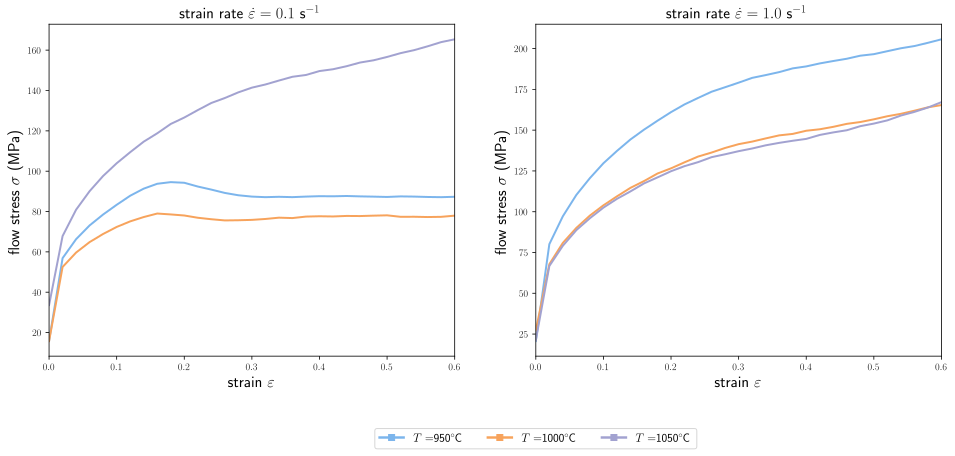

In [3]:
plotDatas(datas, filename='')

<div style="font-size: 28px; font-weight: bold;">ANN Basic Setting</div>

<div style="font-size: 28px; font-weight: bold;">data setting</div>


compute and replace $\dot\varepsilon$ by $\log(\frac{\dot\varepsilon}{\dot\varepsilon_0})$

Compute min and max of ranges

Computes ANNdata

In [4]:
deps0 = depspArray.min()
print('deps0=',deps0)

# since each noeds in the ANN computation should consider the T depsp strain, so expend the datas to shape of [n,4]
strain_data = np.linspace(0, 0.02 * int(len(datas[0][2])-1), num = len(datas[0][2]))
strain = np.asarray(strain_data)
allData = np.concatenate([
    np.column_stack([
        strain,                              # ε
        np.full(len(strain), d[0]),          # depsp
        np.full(len(strain), d[1]),          # T
        np.asarray(d[2])                     # σ
    ])
    for d in datas
])
print('Format of allData', allData.shape)
# change data 
#change strain_rate

allData[:,1] = np.log(allData[:,1] / deps0)
# change to ann data
minData = allData.min(axis=0)

maxData = allData.max(axis=0)

rangeData = maxData - minData

annData = (allData - minData) / rangeData

# set input data and output data
annInput = annData[:,0:3]
annOutput = annData[:,3:4]
# quick look of the training data shape
annInput.shape, annOutput.shape




deps0= 0.1
Format of allData (186, 4)


((186, 3), (186, 1))

<div style="font-size: 28px; font-weight: bold;">ANN structure</div>


In [5]:
# basic setting
models = []
convergence = []
convergences = []

activations =['sigmoid','tanh', 'relu', 'softplus', 'swish', 'exponential']
shapes = [16, 8]

loss = 'mean_squared_error'
optimizer = 'adam'

# model setting
for activation in activations:
    model = Sequential()
    name = str(3)
    layers = shapes if isinstance(shapes, list) else [shapes]
    for i, n in enumerate(layers):
        if i == 0:
            model.add(Dense(n, input_dim=3, activation=activation, name=f'hl-{i}'))
            name += '-'+str(n)
        else:
            model.add(Dense(n, activation=activation, name=f'hl-{i}'))
    name += '-' + str(n)
    model.add(Dense(1, name = 'output'))
    name += '-' + str(1) + '-' + activation
    model._name = name
    models.append(model)
    model.compile(loss = loss, optimizer = optimizer)   
    convergences.append([name, np.array([])])
    






make sure all the models have the same initial conditions

In [6]:
model0 = models[0]
for model in models:
    model.set_weights(model0.get_weights())

for model in models:
    model.summary()

Model: "3-16-8-1-sigmoid"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hl-0 (Dense)                (None, 16)                64        
                                                                 
 hl-1 (Dense)                (None, 8)                 136       
                                                                 
 output (Dense)              (None, 1)                 9         
                                                                 
Total params: 209
Trainable params: 209
Non-trainable params: 0
_________________________________________________________________
Model: "3-16-8-1-tanh"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hl-0 (Dense)                (None, 16)                64        
                                                                 
 hl-1 (Dense)                

In [7]:
for convergence in convergences:
    print(convergence)

['3-16-8-1-sigmoid', array([], dtype=float64)]
['3-16-8-1-tanh', array([], dtype=float64)]
['3-16-8-1-relu', array([], dtype=float64)]
['3-16-8-1-softplus', array([], dtype=float64)]
['3-16-8-1-swish', array([], dtype=float64)]
['3-16-8-1-exponential', array([], dtype=float64)]


<div style="font-size: 28px; font-weight: bold;">ANN Training</div>


In [8]:
#basic setting
epochs = 601
maxIterations = 10
savePeriod = 1
annTraining = False
DataFile = "trained_models"
os.makedirs(DataFile, exist_ok=True)


from sklearn.model_selection import train_test_split
x_train, x_valid, y_train, y_valid = train_test_split(annInput, annOutput, test_size = 0.25, shuffle = True)
x_train.shape, x_valid.shape, y_train.shape, y_valid.shape




((139, 3), (47, 3), (139, 1), (47, 1))

In [9]:

#train route
if annTraining:
    for model, convergence in zip(models, convergences):
        print("Start to train model:", model.name)
        lastMeanLoss = None
        for iteration in range(1, maxIterations + 1):
            history = model.fit(
                x_train, y_train,
                epochs=epochs,
                verbose=0,
                shuffle=True,
                validation_data=(x_valid, y_valid)
            )
            # Only keep the final loss of this full training run
            finalLoss = history.history['loss'][-1]
            convergence[1] = np.append(convergence[1],finalLoss)

            # Print one line per iteration
            if lastMeanLoss is None:
                print(f"Iteration {iteration}: final loss = {finalLoss:.6f}")
            else:
                print(f"Iteration {iteration}: final loss = {finalLoss:.6f} "
                      f"(reduction = {lastMeanLoss - finalLoss:.6f})")
            lastMeanLoss = finalLoss

            # Save every savePeriod iterations
            if iteration % savePeriod == 0:
                model.save(f"{DataFile}/{model.name}.h5")
                writeArrayH5(f"{DataFile}/{model.name}-conv.h5", "data", convergence[1])
                print(f"  saved at iteration {iteration}")

        # Final save
        model.save(f"{DataFile}/{model.name}.h5")
        WriteANNH5(f"{DataFile}/{model.name}-ANN.h5")
        print(f"End of training: {iteration} iterations x {epochs} epochs")
else:
    for model, convergence in zip(models, convergences):
        weightPath = f"{DataFile}/{model.name}.h5"
        convPath = f"{DataFile}/{model.name}-conv.h5"

        if os.path.exists(weightPath):
            try:
                model.load_weights(weightPath)
                print(f"Loaded weights: {weightPath}")
            except Exception as e:
                print(f"Failed to load weights for {model.name}: {e}")
        else:
            print(f"Missing weights file: {weightPath}")

        if os.path.exists(convPath):
            try:
                with h5py.File(convPath, "r") as hf:
                    if "data" in hf:
                        convergence[1] = hf["data"][:]
                        print(
                            f"Loaded convergence: {convPath} "
                            f"(shape={convergence[1].shape})"
                        )
                    else:
                        print(f"No 'data' key in {convPath}. Keys: {list(hf.keys())}")
            except Exception as e:
                print(f"Failed to read {convPath}: {e}")
        else:
            print(f"Missing convergence file: {convPath}")






Loaded weights: trained_models/3-16-8-1-sigmoid.h5
Loaded convergence: trained_models/3-16-8-1-sigmoid-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-tanh.h5
Loaded convergence: trained_models/3-16-8-1-tanh-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-relu.h5
Loaded convergence: trained_models/3-16-8-1-relu-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-softplus.h5
Loaded convergence: trained_models/3-16-8-1-softplus-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-swish.h5
Loaded convergence: trained_models/3-16-8-1-swish-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-exponential.h5
Loaded convergence: trained_models/3-16-8-1-exponential-conv.h5 (shape=(10,))


convergence curve

In [10]:
# mean loss of different models
for convergence in convergences:
    print('%s %.3f x 10-6' %(convergence[0], 1e6*np.mean(convergence[1][-100:])))

3-16-8-1-sigmoid 4789.099 x 10-6
3-16-8-1-tanh 327.491 x 10-6
3-16-8-1-relu 93.595 x 10-6
3-16-8-1-softplus 2507.342 x 10-6
3-16-8-1-swish 594.960 x 10-6
3-16-8-1-exponential 1790.597 x 10-6


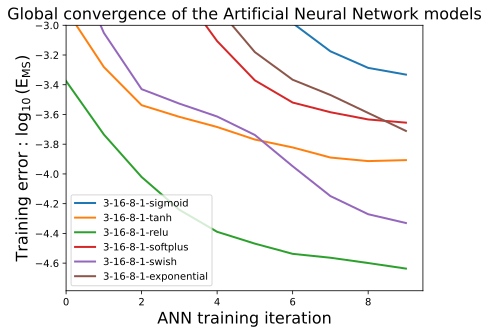

In [11]:
has_data = False
windowLength = 5
# plotDatas() enables usetex; matplotlib's default TeX preamble has no \text (needs amsmath).
plt.rcParams['text.usetex'] = False
for convergence in convergences:
    try:
        convergencef = savgol_filter(np.log10(convergence[1]), window_length=windowLength, polyorder=2)
        plt.plot(convergencef, label=convergence[0], linewidth=2)
        has_data = True
    except Exception as e:
        print(f"Error with {convergence[0]}: {e}")
        continue

if has_data:
    plt.ylim(None, -3)
    plt.xlim(0, None)
    plt.xlabel(r'ANN training iteration', fontsize=16)
    plt.ylabel(r'Training error : $\log_{10}\left(\mathrm{E}_\mathrm{MS}\right)$', fontsize=16)
    plt.title(r'Global convergence of the Artificial Neural Network models', fontsize=16)
    plt.legend()
    if saveFigs:
        plt.savefig("convergence.svg")
    plt.show()
else:
    print("No data to plot.")

<div style="font-size: 28px; font-weight: bold;">Training Result</div>

In [12]:
#predict (using train data)
RMSEA = np.array([])
EAARA = np.array([])
MIXA = np.array([])
for model in models:
    ARstress = (model.predict(annInput, verbose=0)*rangeData[3]+minData[3]).flatten()
    EAAR = np.sum(np.abs((allData[:,3] - ARstress)/(allData[:,3])))*100/ARstress.shape[0]
    RMSE = np.sqrt(np.sum((allData[:,3] - ARstress)**2)/ARstress.shape[0])
    RMSEA = np.append(RMSEA,RMSE)
    EAARA = np.append(EAARA,EAAR)
    MIX = np.sqrt(RMSE**2+EAAR**2)
    MIXA = np.append(MIXA, MIX)
    print("Model %s" %(model.name))
    print('  RMSE = %.2f' %(RMSE)+' MPa')
    print("  EAAR = %.2f" %(EAAR) + ' %')
    print("  Prod = %.3f" %(MIX))

Model 3-16-8-1-sigmoid
  RMSE = 3.60 MPa
  EAAR = 3.60 %
  Prod = 5.089
Model 3-16-8-1-tanh
  RMSE = 2.29 MPa
  EAAR = 2.33 %
  Prod = 3.267
Model 3-16-8-1-relu
  RMSE = 1.31 MPa
  EAAR = 1.29 %
  Prod = 1.839
Model 3-16-8-1-softplus
  RMSE = 3.01 MPa
  EAAR = 2.93 %
  Prod = 4.201
Model 3-16-8-1-swish
  RMSE = 1.77 MPa
  EAAR = 1.81 %
  Prod = 2.526
Model 3-16-8-1-exponential
  RMSE = 3.17 MPa
  EAAR = 2.92 %
  Prod = 4.315


In [13]:
# shorted
SRMSE = np.argsort(RMSEA)
SEAAR = np.argsort(EAARA)
MIXR = np.argsort(MIXA)
for i in SRMSE:
    print('model %s : RMSE=%.3f, ratio=%.3f' %(models[i].name,RMSEA[i],RMSEA[i]/RMSEA[SRMSE[0]]))
print('--------------')
for i in SEAAR:
    print('model %s : EAAR=%.3f, ratio=%.3f' %(models[i].name,EAARA[i],EAARA[i]/EAARA[SEAAR[0]]))
print('--------------')
for i in MIXR:
    print('model %s : MIX=%.3f, ratio=%.3f' %(models[i].name,MIXA[i],MIXA[i]/MIXA[MIXR[0]]))

model 3-16-8-1-relu : RMSE=1.315, ratio=1.000
model 3-16-8-1-swish : RMSE=1.767, ratio=1.344
model 3-16-8-1-tanh : RMSE=2.288, ratio=1.741
model 3-16-8-1-softplus : RMSE=3.014, ratio=2.293
model 3-16-8-1-exponential : RMSE=3.173, ratio=2.413
model 3-16-8-1-sigmoid : RMSE=3.602, ratio=2.740
--------------
model 3-16-8-1-relu : EAAR=1.286, ratio=1.000
model 3-16-8-1-swish : EAAR=1.805, ratio=1.404
model 3-16-8-1-tanh : EAAR=2.331, ratio=1.813
model 3-16-8-1-exponential : EAAR=2.925, ratio=2.275
model 3-16-8-1-softplus : EAAR=2.926, ratio=2.276
model 3-16-8-1-sigmoid : EAAR=3.595, ratio=2.796
--------------
model 3-16-8-1-relu : MIX=1.839, ratio=1.000
model 3-16-8-1-swish : MIX=2.526, ratio=1.374
model 3-16-8-1-tanh : MIX=3.267, ratio=1.776
model 3-16-8-1-softplus : MIX=4.201, ratio=2.284
model 3-16-8-1-exponential : MIX=4.315, ratio=2.347
model 3-16-8-1-sigmoid : MIX=5.089, ratio=2.768


plot the result

In [14]:
def plotResultsOfModel(model):
    Ts = getTArray(datas)
    depsps = getDepspArray(datas)
    ndepsp = depsps.shape[0]
    nT = Ts.shape[0]
    plt.figure(figsize = sbPlotSize(ndepsp))
    plt.rc('text', usetex = True)
    plt.subplots_adjust(hspace = 0.3)
    xs, ys = sbPlot(ndepsp)
    idx = 1
    for depsp in depsps:
        plt.subplot(xs, ys, idx)
        cl = 0
        for T in Ts:
            for d in datas:
                if (d[0] == depsp and d[1] == T):
                    subdata = d[2]
                    arr_x = np.linspace(0, 0.02 * int(len(subdata)-1), num = len(subdata))
                    plt.plot(arr_x, subdata, label=r'$T=' + str(d[1]) + '^{\circ}C$', linewidth = 2, color=colors[cl])
                    inp = np.zeros((subdata.shape[0],3))
                    inp[:,0] = (arr_x - minData[0]) / rangeData[0]
                    inp[:,1] = (np.log(depsp / deps0) - minData[1]) / rangeData[1]
                    inp[:,2]  = (T - minData[2]) / rangeData[2]
                    plt.plot(arr_x,model.predict(inp, verbose=0)*rangeData[3]+minData[3],colors[cl], linewidth = 2.5)
            cl += 1
        plt.xlabel(r'strain $\varepsilon$', fontsize = 16) # Labels the x axis
        plt.ylabel(r'flow stress $\sigma$ (MPa)', fontsize = 16) # Labels the y axis
        plt.title(r'strain rate $\dot{\varepsilon} = ' + str(depsp) + '$ s$^{-1}$', fontsize = 16) # Self explicit command
        plt.xlim(arr_x.min(), arr_x.max())
        plt.ylim(0, None)
        idx += 1
        
    legendLines = []
    cl = 0
    for temp in list(Ts):
        legendLines.append((r'$T=$' + str(int(temp)) + r'$^{\circ}$C', {'color':colors[cl], 'linestyle':'-', 'linewidth':2.5, 'marker':'s'}))
        cl += 1
    
    if (ndepsp % 2):
        plt.legend([create_dummy_line(**l[1]) for l in legendLines], [l[0] for l in legendLines], 
               loc = 'upper center', fontsize = 12, ncols = 6, bbox_to_anchor = (1.0, -0.2), shadow = False)
    else:
        plt.legend([create_dummy_line(**l[1]) for l in legendLines], [l[0] for l in legendLines], 
               loc = 'upper center', fontsize = 12, ncols = 6, bbox_to_anchor = (0.0, -0.2), shadow = False)
        
    #if (saveFigs):
      #  plt.savefig('Figures/' + DataFile + '-' + model.name + '.svg')
    
    plt.show()

display

3-16-8-1-sigmoid


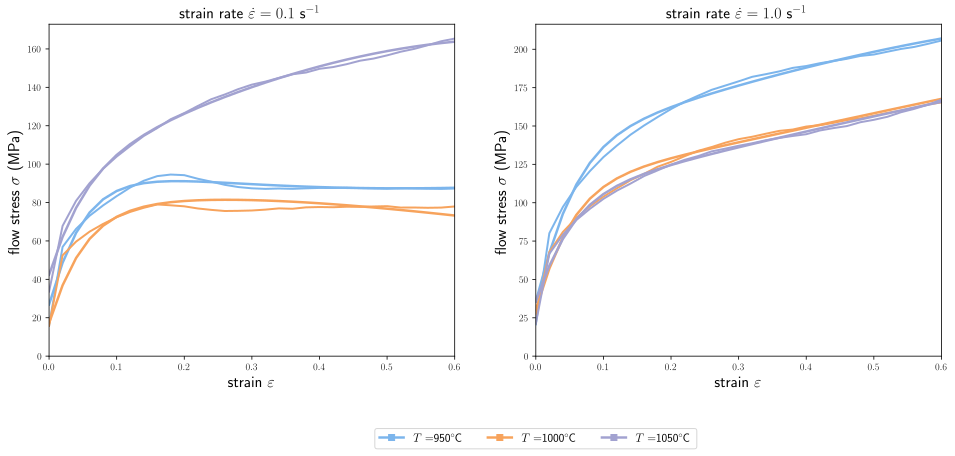

3-16-8-1-tanh


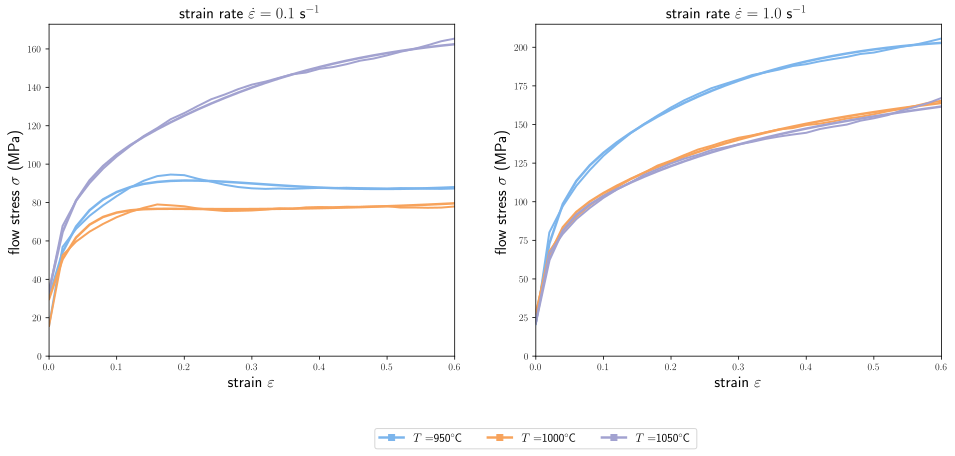

3-16-8-1-relu


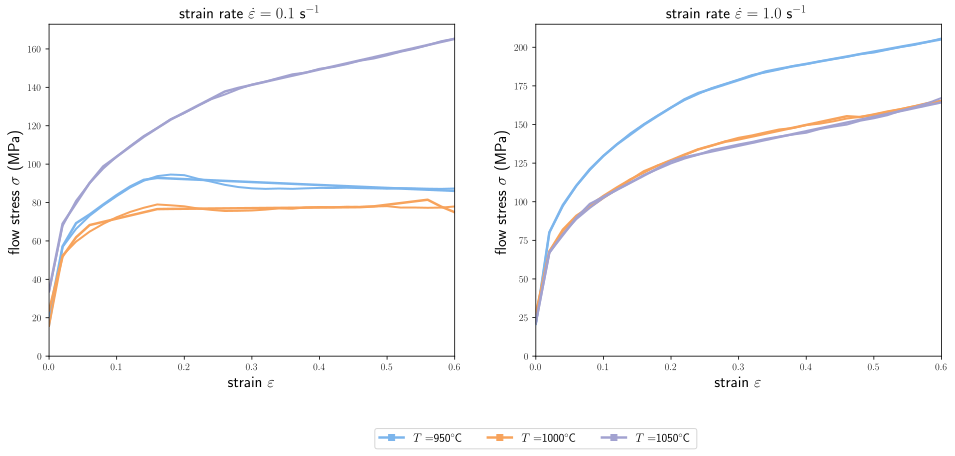

3-16-8-1-softplus


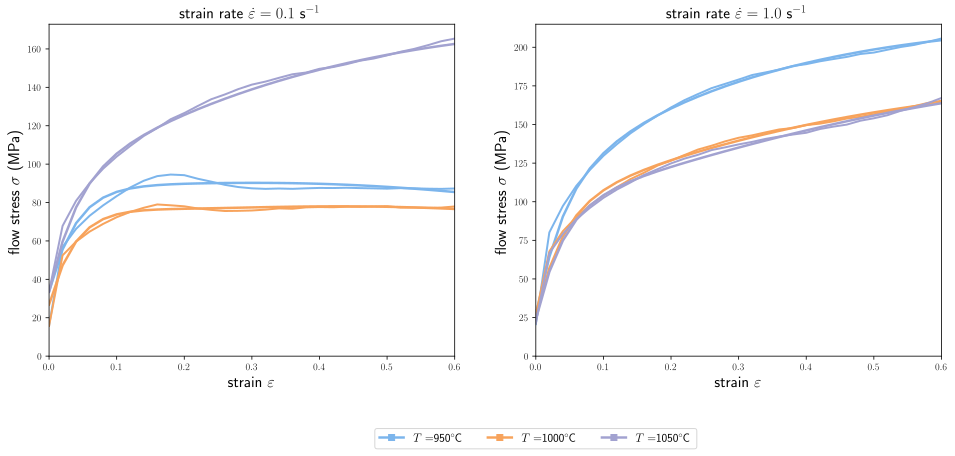

3-16-8-1-swish


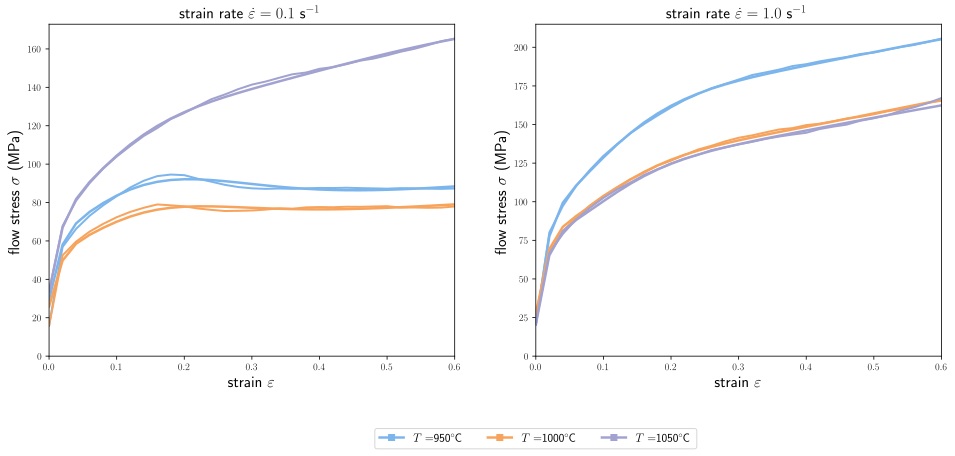

3-16-8-1-exponential


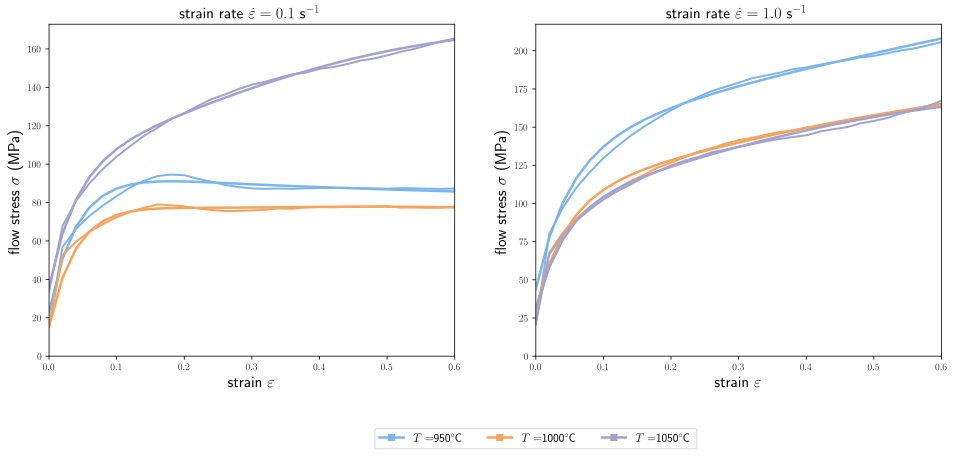

In [15]:
if (plotFigs):
    for model in models:
        print(model.name)
        plotResultsOfModel(model)